# 08.01 — Brick 1: Data Construction and Corpus Funnel

This notebook is **only Brick 1**.

It does not interpret communities.  
It does not discuss centrality.  
It does not model success.

Its job is to answer one basic reader question:

> What data did the thesis start with, and how did it become the final analysis corpus?

## Figures produced

```text
outputs/thesis_bricks/01_data_construction/figures/
```

1. `01_data_funnel_main.png`  
2. `02_year_coverage_semantic_corpus.png`  
3. `03_year_coverage_final_network.png`  
4. `04_variable_availability.png`  
5. `05_revenue_coverage_by_year.png`  
6. `06_vote_count_distribution_semantic.png`  
7. `07_data_construction_summary_cards.png`  

## Tables produced

```text
outputs/thesis_bricks/01_data_construction/tables/
```

These are clean supporting tables, not main thesis tables.


## 0. Setup

In [1]:

import os, re, math, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 160)
pd.set_option("display.max_colwidth", 180)

COL = {
    "ink": "#222222",
    "muted": "#62666D",
    "grid": "#E4E7EB",
    "panel": "#F7F8FA",
    "blue": "#2F6FB3",
    "orange": "#D06C45",
    "green": "#2F8F5B",
    "purple": "#7A5BC2",
    "red": "#C94C4C",
    "light_blue": "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green": "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray": "#F2F4F7",
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COL["ink"],
    "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink"],
    "ytick.color": COL["ink"],
    "text.color": COL["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": 320,
    "figure.dpi": 130,
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def title_block(fig, title, subtitle=None, x=0.06, y=0.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def fmt_int(x):
    try:
        return f"{int(x):,}"
    except Exception:
        return "—"

def safe_read(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print("Missing:", path)
    return None


## 1. Project paths

In [2]:

try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "01_data_construction"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:", FINAL_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction


## 2. Load data files

In [3]:

FILES = {
    "df_thesis": PROCESSED_CORE_DIR / "df_thesis_films.csv",
    "df_semantic": PROCESSED_CORE_DIR / "df_semantic_analysis.csv",
    "df_display": PROCESSED_CORE_DIR / "df_display_candidates.csv",
    "df_revenue": PROCESSED_CORE_DIR / "df_revenue_analysis.csv",
    "df_roi": PROCESSED_CORE_DIR / "df_roi_analysis.csv",
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "network_basic": OUTPUT_TABLES_DIR / "network_interpretation_basic_checks.csv",
    "modeling": PROCESSED_FEATURES_DIR / "modeling_table_success_star_power.csv",
}

for k, p in FILES.items():
    print(f"{k:16s}", p.exists(), "-", p)

df_thesis = safe_read(FILES["df_thesis"])
df_semantic = safe_read(FILES["df_semantic"])
df_display = safe_read(FILES["df_display"])
df_revenue = safe_read(FILES["df_revenue"])
df_roi = safe_read(FILES["df_roi"])
nodes = safe_read(FILES["nodes"])
network_basic = safe_read(FILES["network_basic"])
modeling = safe_read(FILES["modeling"])

loaded = {
    "df_thesis": df_thesis,
    "df_semantic": df_semantic,
    "df_display": df_display,
    "df_revenue": df_revenue,
    "df_roi": df_roi,
    "nodes": nodes,
    "modeling": modeling,
}
print()
for k, df in loaded.items():
    if df is not None:
        print(f"{k:16s}", df.shape)


df_thesis        True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_thesis_films.csv
df_semantic      True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_semantic_analysis.csv
df_display       True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_display_candidates.csv
df_revenue       True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_revenue_analysis.csv
df_roi           True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_roi_analysis.csv
nodes            True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
network_basic    True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/network_interpretation_basic_checks.csv
modeling         True - /content/drive/MyDrive/thesis_movie_project/processed/features/modeling_table_success_star_power.csv

df_thesis        (98037, 24)
df_semantic      (20091, 17)
df_display       (13965, 17)
df_revenue       

## 3. Figure 1 — Main data funnel

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/tables/01_data_funnel_main_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/01_data_funnel_main.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/01_data_funnel_main.svg


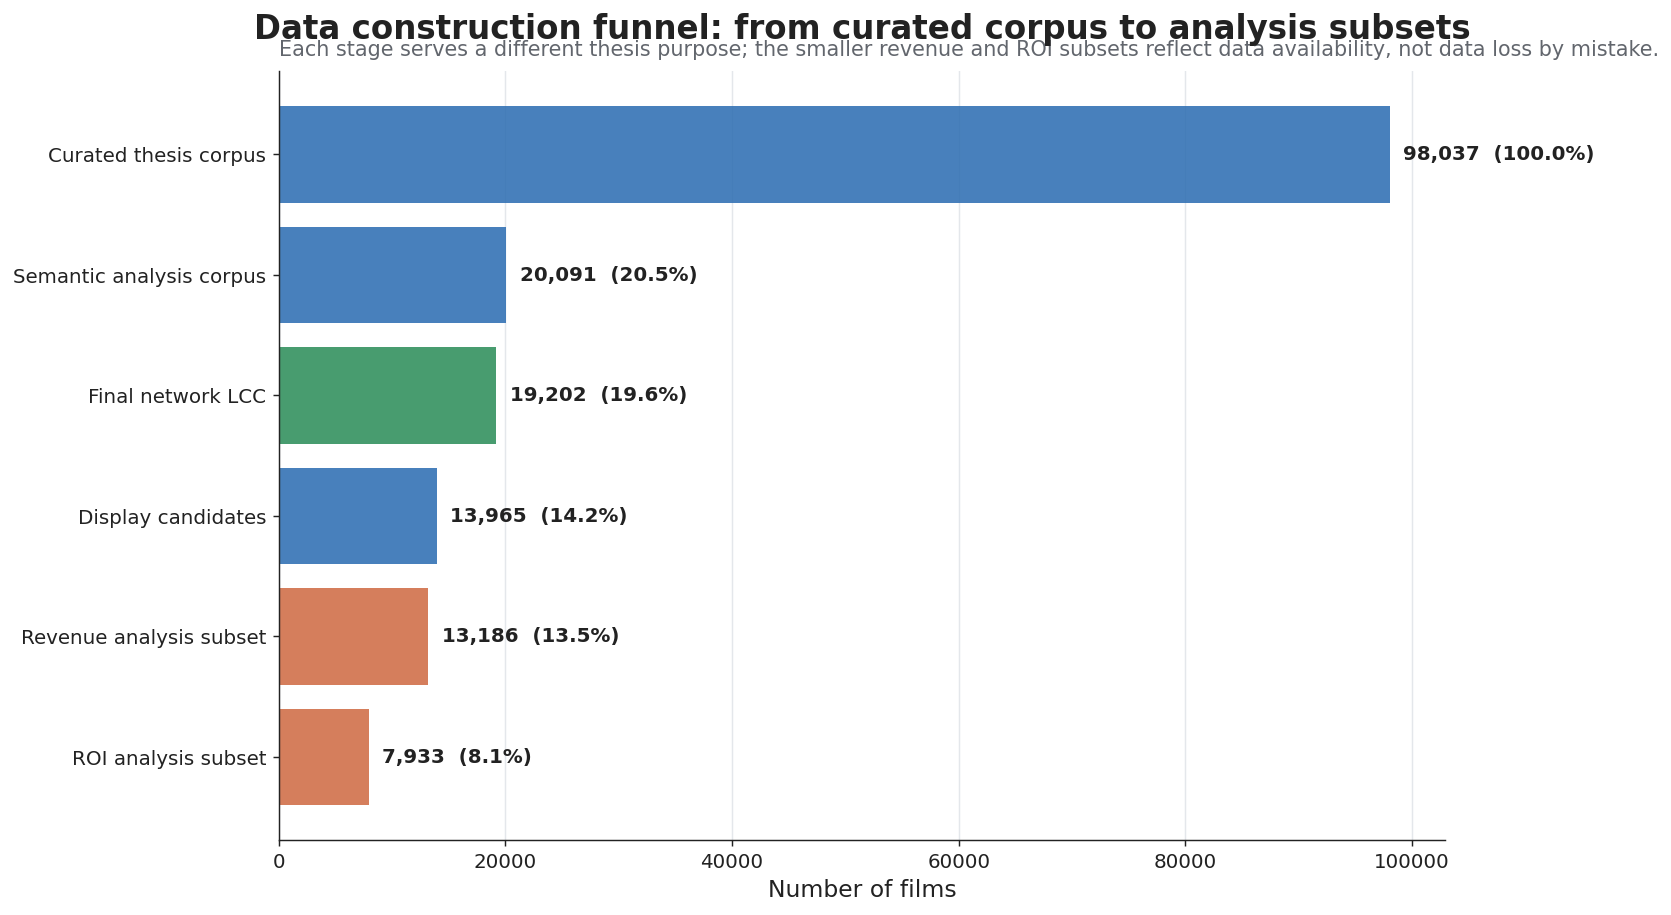

In [4]:

rows = []
stage_order = [
    ("df_thesis", "Curated thesis corpus", "all released feature-length non-documentary films after core filters"),
    ("df_semantic", "Semantic analysis corpus", "films with usable plot text and minimum audience signal"),
    ("nodes", "Final network LCC", "films in largest connected component of the plot-similarity graph"),
    ("df_display", "Display candidates", "films suitable for recognizable examples and figures"),
    ("df_revenue", "Revenue analysis subset", "films with usable revenue information"),
    ("df_roi", "ROI analysis subset", "films with usable budget and revenue information"),
]

for key, label, purpose in stage_order:
    df = loaded.get(key)
    if df is not None:
        rows.append({"stage": label, "n_films": len(df), "purpose": purpose})

funnel = pd.DataFrame(rows)
base_n = funnel["n_films"].iloc[0]
funnel["share_of_curated_pct"] = funnel["n_films"] / base_n * 100

save_table(funnel, "01_data_funnel_main_table.csv")

plot_df = funnel.sort_values("n_films", ascending=True)

fig, ax = plt.subplots(figsize=(12.5, 7.2))

colors = []
for s in plot_df["stage"]:
    if "Revenue" in s or "ROI" in s:
        colors.append(COL["orange"])
    elif "network" in s.lower():
        colors.append(COL["green"])
    else:
        colors.append(COL["blue"])

bars = ax.barh(plot_df["stage"], plot_df["n_films"], color=colors, alpha=0.88)

for bar, (_, r) in zip(bars, plot_df.iterrows()):
    ax.text(
        bar.get_width() + base_n * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{fmt_int(r['n_films'])}  ({r['share_of_curated_pct']:.1f}%)",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title("Data construction funnel: from curated corpus to analysis subsets", pad=18)
ax.text(
    0, 1.02,
    "Each stage serves a different thesis purpose; the smaller revenue and ROI subsets reflect data availability, not data loss by mistake.",
    transform=ax.transAxes,
    fontsize=11.5,
    color=COL["muted"]
)
ax.set_xlabel("Number of films")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=COL["grid"])
ax.set_axisbelow(True)

plt.tight_layout()
save_fig(fig, "01_data_funnel_main.png")
plt.show()


## 4. Figure 2 — Year coverage of semantic corpus

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/tables/02_year_coverage_semantic_corpus_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/02_year_coverage_semantic_corpus.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/02_year_coverage_semantic_corpus.svg


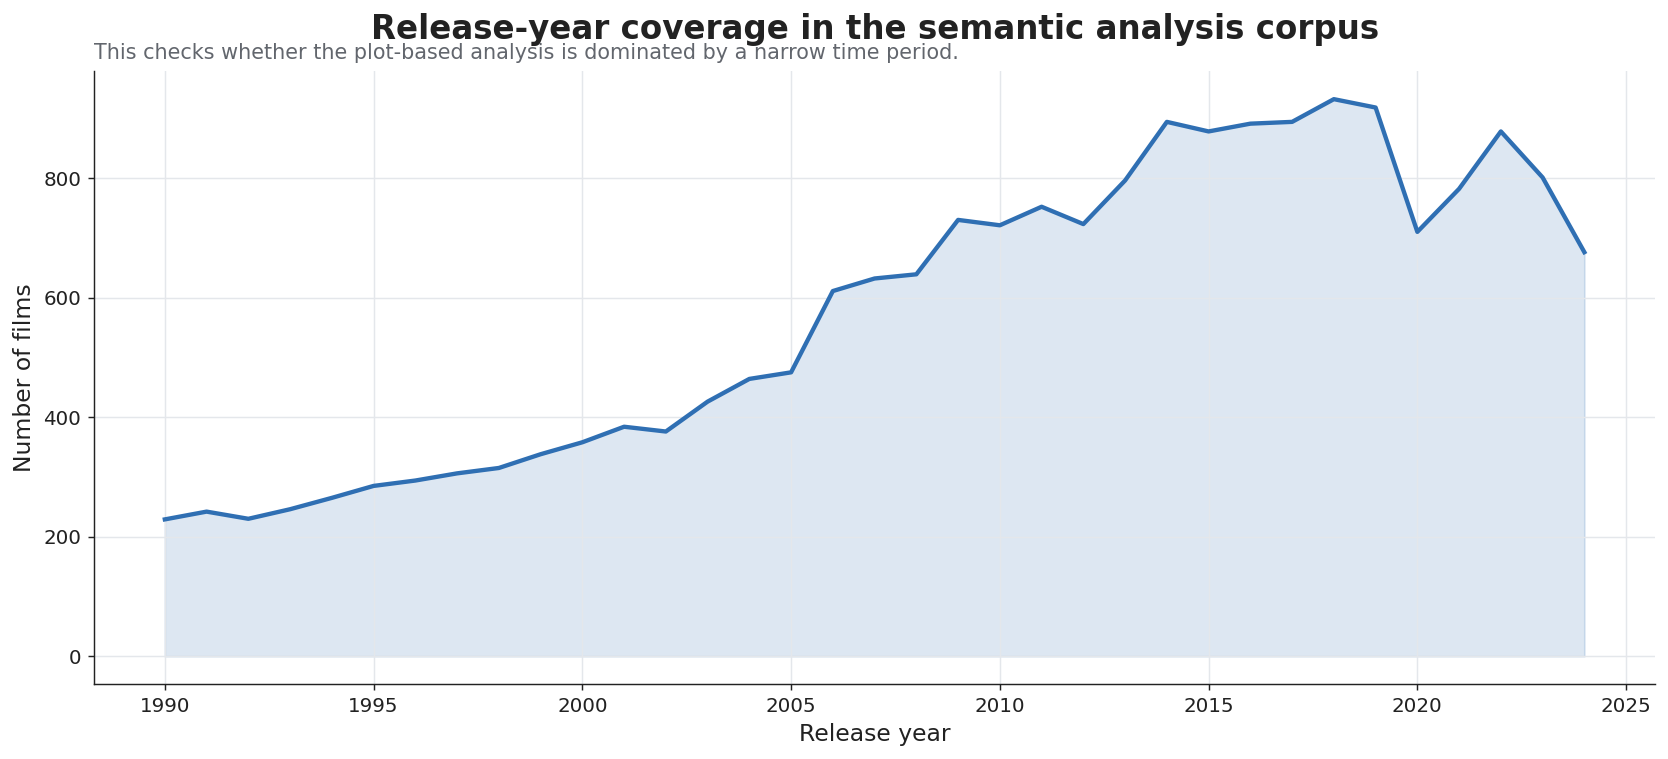

In [5]:

df = df_semantic if df_semantic is not None else nodes
year_col = "release_year" if df is not None and "release_year" in df.columns else None

if df is not None and year_col:
    temp = df.dropna(subset=[year_col]).copy()
    temp[year_col] = temp[year_col].astype(int)
    counts = temp.groupby(year_col).size().reset_index(name="n_films")
    save_table(counts, "02_year_coverage_semantic_corpus_table.csv")

    fig, ax = plt.subplots(figsize=(13, 6))
    ax.plot(counts[year_col], counts["n_films"], color=COL["blue"], lw=2.4)
    ax.fill_between(counts[year_col], counts["n_films"], color=COL["blue"], alpha=0.16)

    ax.set_title("Release-year coverage in the semantic analysis corpus", pad=18)
    ax.text(
        0, 1.02,
        "This checks whether the plot-based analysis is dominated by a narrow time period.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Release year")
    ax.set_ylabel("Number of films")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=COL["grid"])

    plt.tight_layout()
    save_fig(fig, "02_year_coverage_semantic_corpus.png")
    plt.show()
else:
    print("No release_year column found.")


## 5. Figure 3 — Year coverage of final network

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/tables/03_year_coverage_final_network_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/03_year_coverage_final_network.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/03_year_coverage_final_network.svg


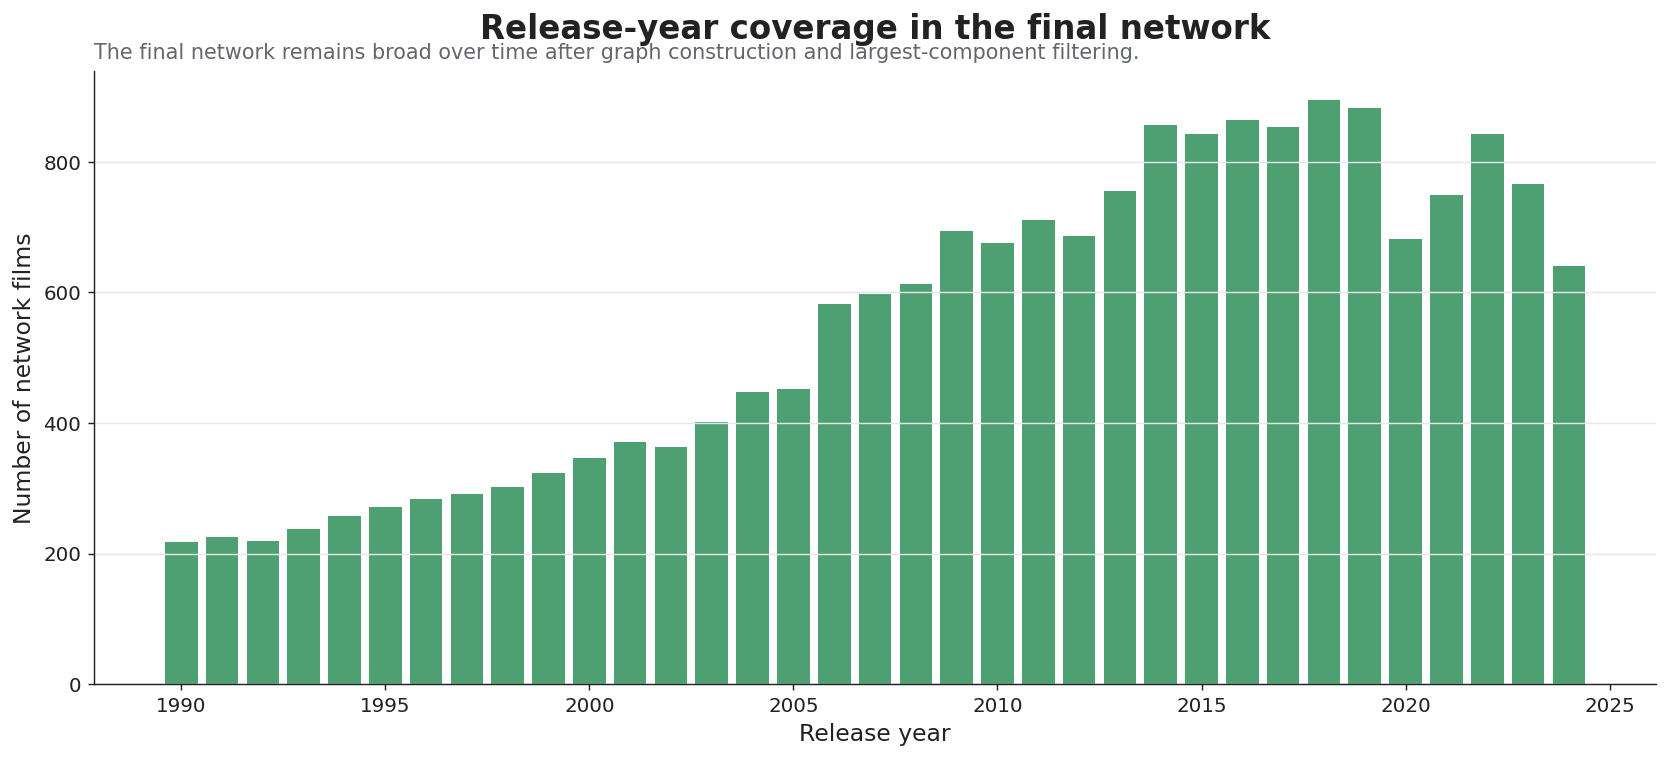

In [6]:

df = nodes
year_col = "release_year" if df is not None and "release_year" in df.columns else None

if df is not None and year_col:
    temp = df.dropna(subset=[year_col]).copy()
    temp[year_col] = temp[year_col].astype(int)
    counts = temp.groupby(year_col).size().reset_index(name="n_films")
    save_table(counts, "03_year_coverage_final_network_table.csv")

    fig, ax = plt.subplots(figsize=(13, 6))
    ax.bar(counts[year_col], counts["n_films"], color=COL["green"], alpha=0.85)

    ax.set_title("Release-year coverage in the final network", pad=18)
    ax.text(
        0, 1.02,
        "The final network remains broad over time after graph construction and largest-component filtering.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Release year")
    ax.set_ylabel("Number of network films")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])

    plt.tight_layout()
    save_fig(fig, "03_year_coverage_final_network.png")
    plt.show()
else:
    print("No release_year column found in nodes.")


## 6. Figure 4 — Variable availability

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/tables/04_variable_availability_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/04_variable_availability.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/04_variable_availability.svg


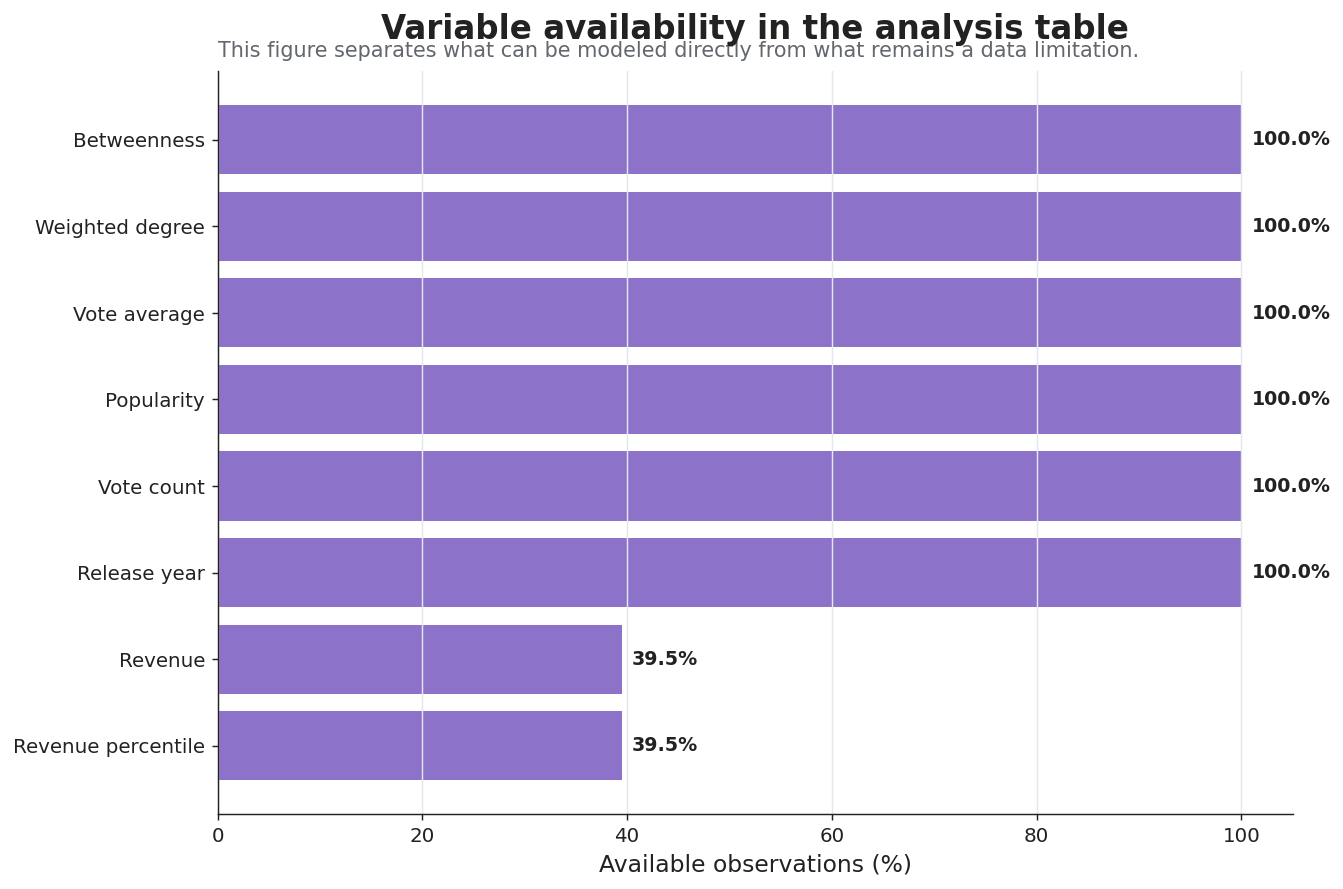

In [7]:

df = modeling if modeling is not None else nodes

if df is not None:
    candidates = [
        ("overview", "Plot text"),
        ("release_year", "Release year"),
        ("vote_count", "Vote count"),
        ("vote_average", "Vote average"),
        ("popularity", "Popularity"),
        ("revenue_clean", "Revenue"),
        ("budget_clean", "Budget"),
        ("revenue_percentile_year", "Revenue percentile"),
        ("weighted_degree", "Weighted degree"),
        ("betweenness_centrality_sampled", "Betweenness"),
    ]

    rows = []
    for col, label in candidates:
        if col in df.columns:
            rows.append({
                "variable": label,
                "column": col,
                "available_pct": df[col].notna().mean() * 100,
                "n_available": int(df[col].notna().sum())
            })

    availability = pd.DataFrame(rows).sort_values("available_pct", ascending=True)
    save_table(availability, "04_variable_availability_table.csv")

    fig, ax = plt.subplots(figsize=(10.5, 7))
    ax.barh(availability["variable"], availability["available_pct"], color=COL["purple"], alpha=0.86)

    for i, (_, r) in enumerate(availability.iterrows()):
        ax.text(
            r["available_pct"] + 1,
            i,
            f"{r['available_pct']:.1f}%",
            va="center",
            fontsize=10.5,
            fontweight="bold"
        )

    ax.set_xlim(0, 105)
    ax.set_title("Variable availability in the analysis table", pad=18)
    ax.text(
        0, 1.02,
        "This figure separates what can be modeled directly from what remains a data limitation.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Available observations (%)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color=COL["grid"])

    plt.tight_layout()
    save_fig(fig, "04_variable_availability.png")
    plt.show()
else:
    print("No modeling or nodes table found.")


## 7. Figure 5 — Revenue coverage by year

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/tables/05_revenue_coverage_by_year_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/05_revenue_coverage_by_year.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/05_revenue_coverage_by_year.svg


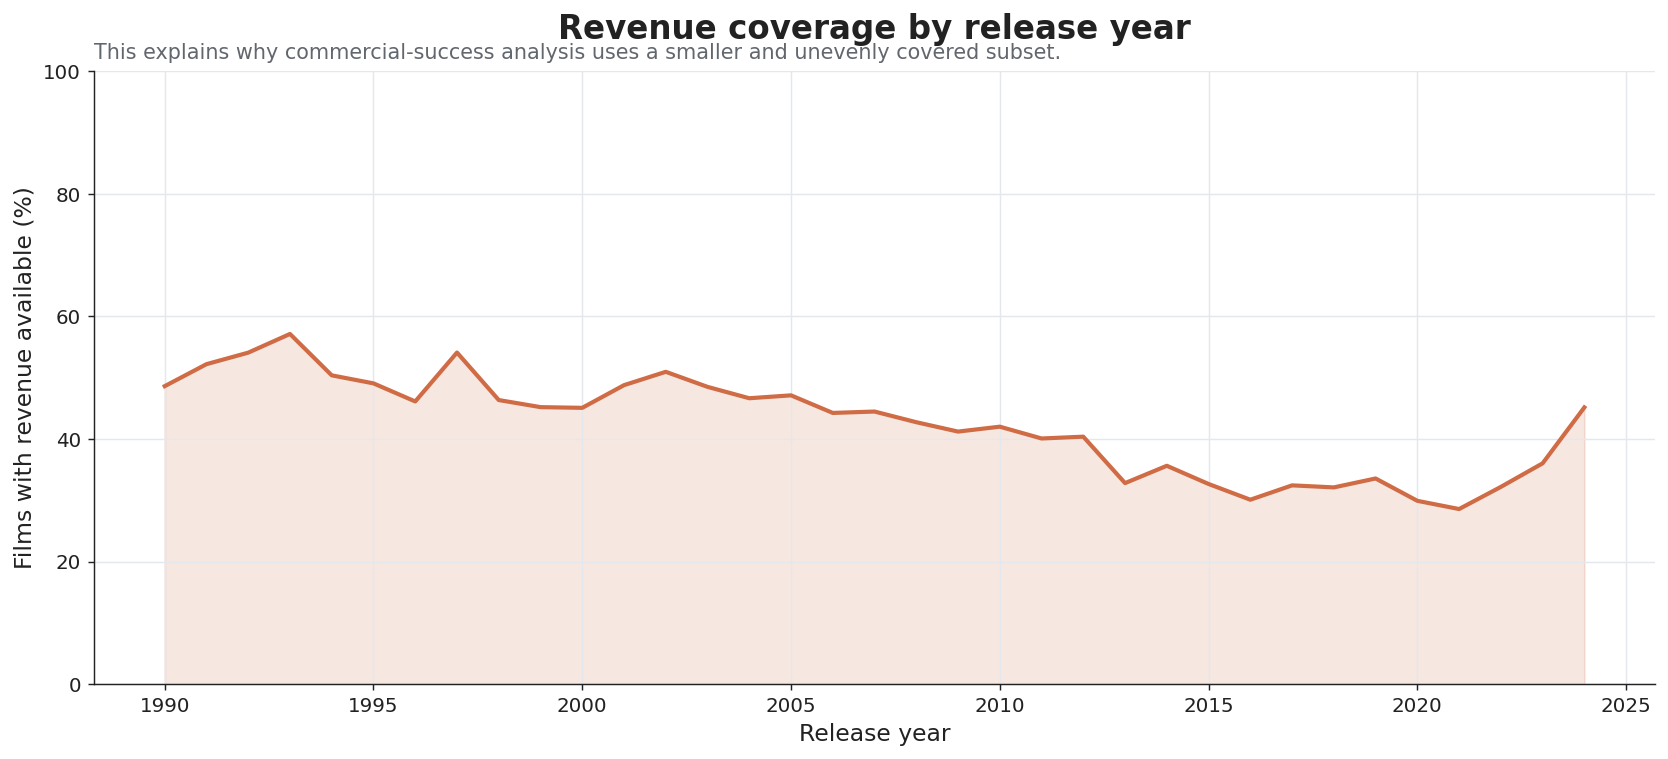

In [8]:

df = modeling if modeling is not None else nodes

if df is not None and "release_year" in df.columns:
    revenue_col = "revenue_clean" if "revenue_clean" in df.columns else None

    if revenue_col:
        temp = df.dropna(subset=["release_year"]).copy()
        temp["release_year"] = temp["release_year"].astype(int)
        yearly = (
            temp
            .groupby("release_year")
            .agg(
                n_films=("release_year", "size"),
                n_revenue=(revenue_col, lambda x: x.notna().sum())
            )
            .reset_index()
        )
        yearly["revenue_coverage_pct"] = yearly["n_revenue"] / yearly["n_films"] * 100
        save_table(yearly, "05_revenue_coverage_by_year_table.csv")

        fig, ax = plt.subplots(figsize=(13, 6))
        ax.plot(yearly["release_year"], yearly["revenue_coverage_pct"], color=COL["orange"], lw=2.3)
        ax.fill_between(yearly["release_year"], yearly["revenue_coverage_pct"], color=COL["orange"], alpha=0.16)

        ax.set_title("Revenue coverage by release year", pad=18)
        ax.text(
            0, 1.02,
            "This explains why commercial-success analysis uses a smaller and unevenly covered subset.",
            transform=ax.transAxes,
            fontsize=11.5,
            color=COL["muted"]
        )
        ax.set_xlabel("Release year")
        ax.set_ylabel("Films with revenue available (%)")
        ax.set_ylim(0, max(100, yearly["revenue_coverage_pct"].max() * 1.08))
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(color=COL["grid"])

        plt.tight_layout()
        save_fig(fig, "05_revenue_coverage_by_year.png")
        plt.show()
    else:
        print("No revenue_clean column found.")
else:
    print("No release_year column found.")


## 8. Figure 6 — Vote-count distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/tables/06_vote_count_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/06_vote_count_distribution_semantic.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/06_vote_count_distribution_semantic.svg


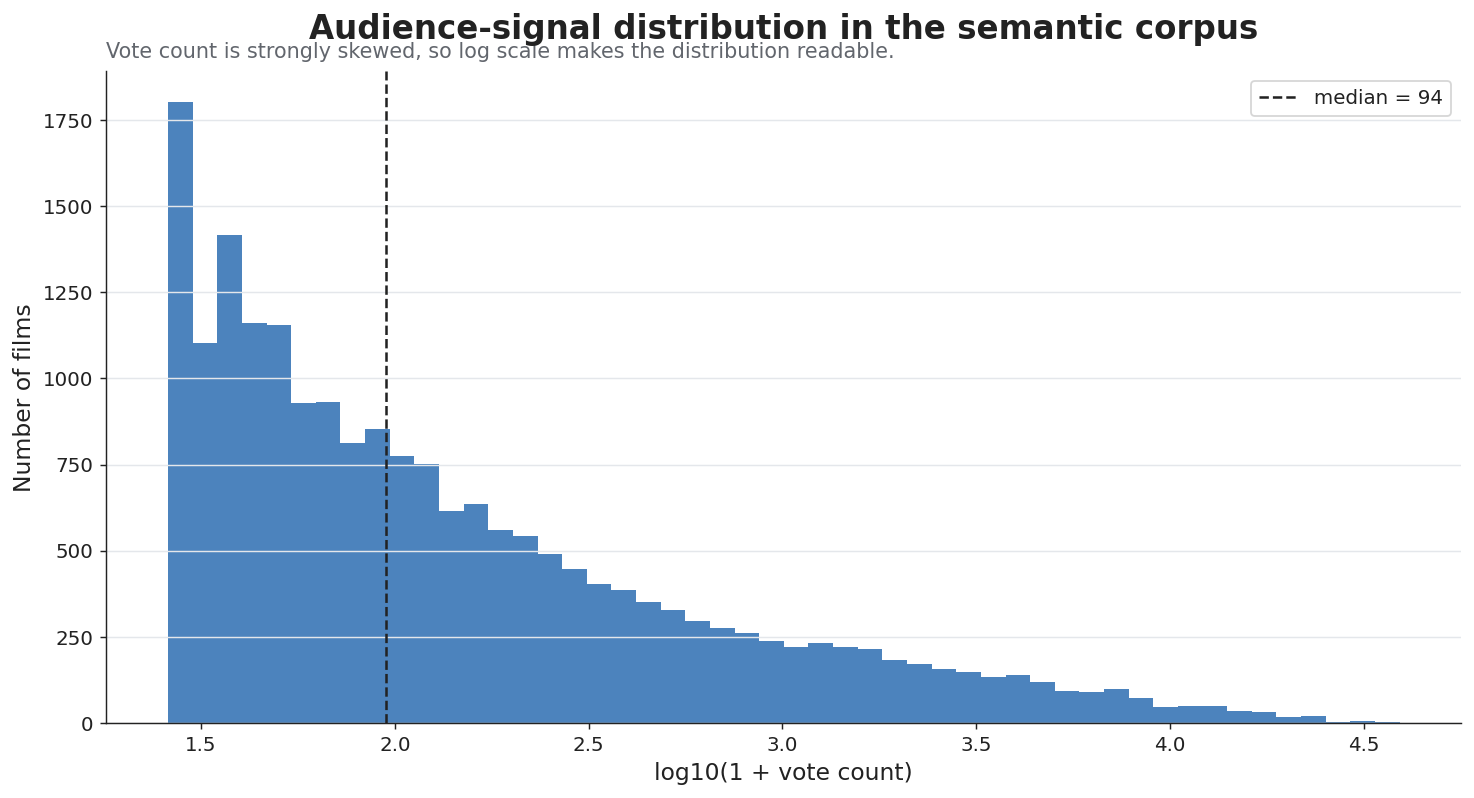

In [9]:

df = df_semantic if df_semantic is not None else nodes

if df is not None and "vote_count" in df.columns:
    x = df["vote_count"].dropna().clip(lower=0)
    x_log = np.log10(x + 1)

    summary = pd.DataFrame({
        "metric": ["n", "median_vote_count", "mean_vote_count", "p75_vote_count", "p90_vote_count"],
        "value": [len(x), x.median(), x.mean(), x.quantile(0.75), x.quantile(0.90)]
    })
    save_table(summary, "06_vote_count_distribution_summary.csv")

    fig, ax = plt.subplots(figsize=(11.5, 6.3))
    ax.hist(x_log, bins=50, color=COL["blue"], alpha=0.86)

    ax.axvline(np.log10(x.median() + 1), color=COL["ink"], ls="--", lw=1.4, label=f"median = {x.median():.0f}")

    ax.set_title("Audience-signal distribution in the semantic corpus", pad=18)
    ax.text(
        0, 1.02,
        "Vote count is strongly skewed, so log scale makes the distribution readable.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("log10(1 + vote count)")
    ax.set_ylabel("Number of films")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])
    ax.legend()

    plt.tight_layout()
    save_fig(fig, "06_vote_count_distribution_semantic.png")
    plt.show()
else:
    print("No vote_count column found.")


## 9. Figure 7 — Data construction summary cards

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/07_data_construction_summary_cards.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/figures/07_data_construction_summary_cards.svg


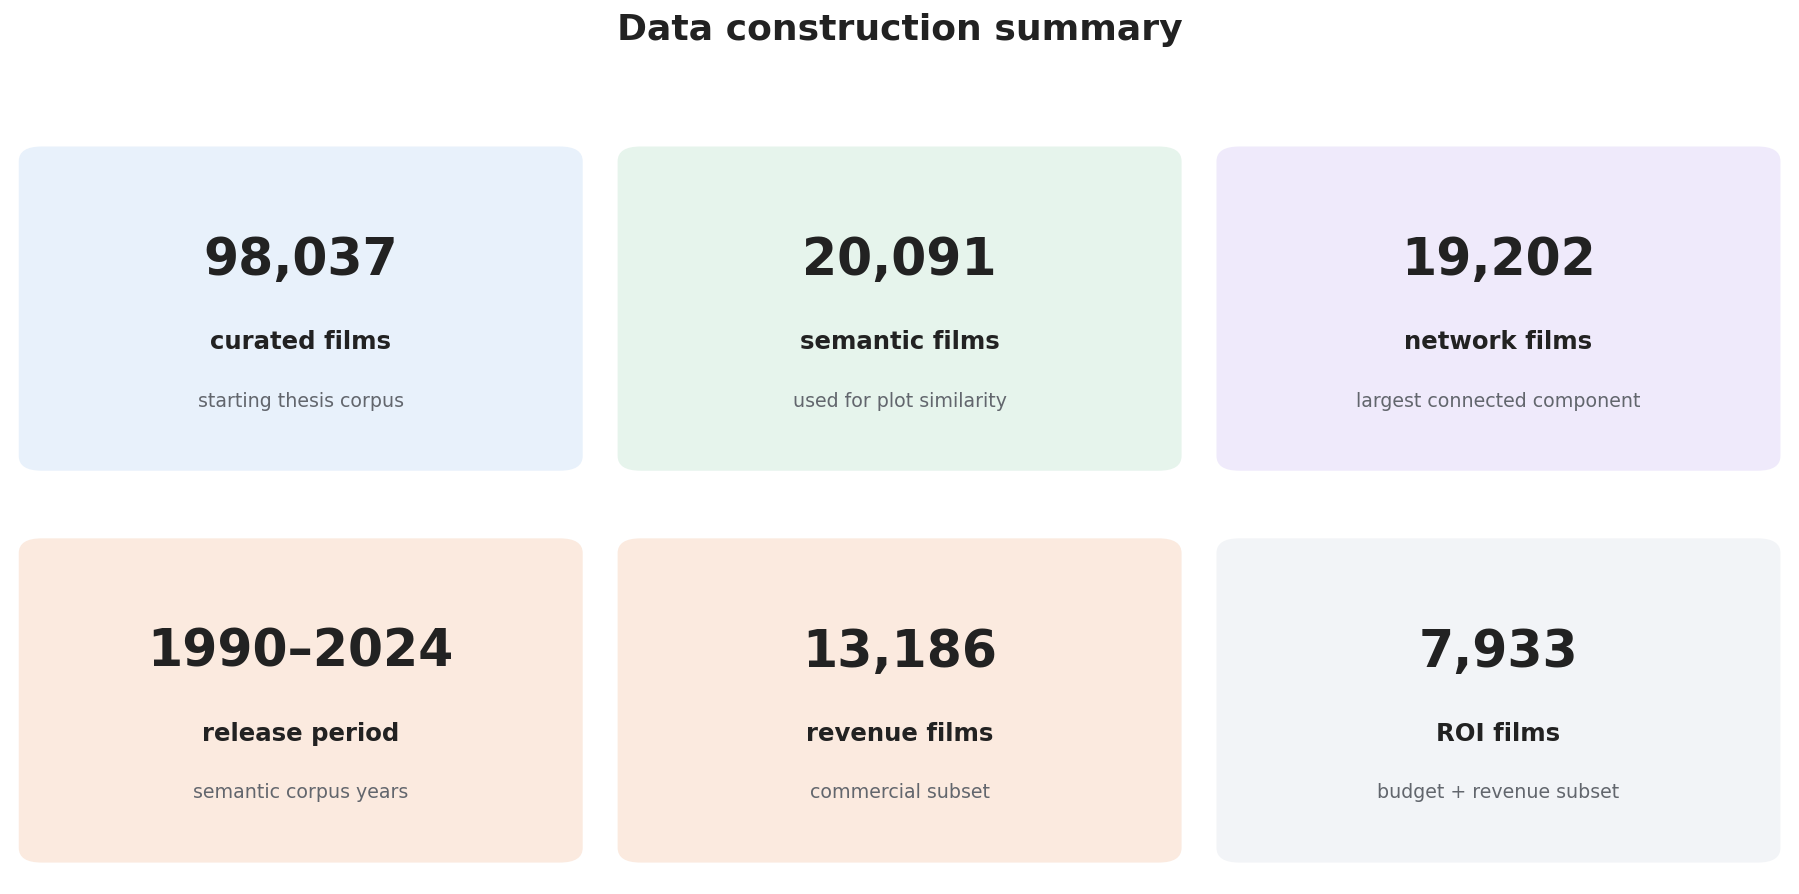

In [10]:

# Build cards from available data.
n_thesis = len(df_thesis) if df_thesis is not None else np.nan
n_semantic = len(df_semantic) if df_semantic is not None else np.nan
n_nodes = len(nodes) if nodes is not None else np.nan
n_revenue = len(df_revenue) if df_revenue is not None else np.nan
n_roi = len(df_roi) if df_roi is not None else np.nan

min_year = max_year = np.nan
if df_semantic is not None and "release_year" in df_semantic.columns:
    yy = df_semantic["release_year"].dropna()
    if len(yy):
        min_year, max_year = int(yy.min()), int(yy.max())

cards = [
    (fmt_int(n_thesis), "curated films", "starting thesis corpus", COL["light_blue"]),
    (fmt_int(n_semantic), "semantic films", "used for plot similarity", COL["light_green"]),
    (fmt_int(n_nodes), "network films", "largest connected component", COL["light_purple"]),
    (f"{min_year}–{max_year}" if not pd.isna(min_year) else "—", "release period", "semantic corpus years", COL["light_orange"]),
    (fmt_int(n_revenue), "revenue films", "commercial subset", COL["light_orange"]),
    (fmt_int(n_roi), "ROI films", "budget + revenue subset", COL["light_gray"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (value, title, subtitle, bg) in zip(axes, cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=28, fontweight="bold")
    ax.text(0.5, 0.40, title, ha="center", va="center", fontsize=13.5, fontweight="bold")
    ax.text(0.5, 0.24, subtitle, ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("Data construction summary", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "07_data_construction_summary_cards.png")
plt.show()


## 10. Export a short interpretation note

In [11]:

note = f"""
Brick 1 — Data construction interpretation note

This section should appear in the Data chapter or at the beginning of Results.

Main message:
The thesis starts from a broad curated film corpus and then creates specific analysis subsets for semantic similarity, network construction, display examples, revenue analysis, and ROI analysis.

Recommended figures for main thesis:
1. 01_data_funnel_main.png
2. 02_year_coverage_semantic_corpus.png
3. 04_variable_availability.png
4. 07_data_construction_summary_cards.png

Recommended appendix/supporting figures:
1. 03_year_coverage_final_network.png
2. 05_revenue_coverage_by_year.png
3. 06_vote_count_distribution_semantic.png

Important wording:
The smaller revenue and ROI subsets should be described as data-availability constraints, not as mistakes or arbitrary exclusions.
""".strip()

path = TEXT_DIR / "brick_01_interpretation_note.txt"
path.write_text(note, encoding="utf-8")
print(note)
print("Saved:", path)


Brick 1 — Data construction interpretation note

This section should appear in the Data chapter or at the beginning of Results.

Main message:
The thesis starts from a broad curated film corpus and then creates specific analysis subsets for semantic similarity, network construction, display examples, revenue analysis, and ROI analysis.

Recommended figures for main thesis:
1. 01_data_funnel_main.png
2. 02_year_coverage_semantic_corpus.png
3. 04_variable_availability.png
4. 07_data_construction_summary_cards.png

Recommended appendix/supporting figures:
1. 03_year_coverage_final_network.png
2. 05_revenue_coverage_by_year.png
3. 06_vote_count_distribution_semantic.png

Important wording:
The smaller revenue and ROI subsets should be described as data-availability constraints, not as mistakes or arbitrary exclusions.
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/01_data_construction/text/brick_01_interpretation_note.txt


## 11. Output check

In [12]:

print("Figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)

print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)

print("\nText:")
for p in sorted(TEXT_DIR.glob("*.txt")):
    print("-", p.name)


Figures:
- 01_data_funnel_main.png
- 02_year_coverage_semantic_corpus.png
- 03_year_coverage_final_network.png
- 04_variable_availability.png
- 05_revenue_coverage_by_year.png
- 06_vote_count_distribution_semantic.png
- 07_data_construction_summary_cards.png

Tables:
- 01_data_funnel_main_table.csv
- 02_year_coverage_semantic_corpus_table.csv
- 03_year_coverage_final_network_table.csv
- 04_variable_availability_table.csv
- 05_revenue_coverage_by_year_table.csv
- 06_vote_count_distribution_summary.csv

Text:
- brick_01_interpretation_note.txt
